<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/01_data_collection_and_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

!pip install -q yfinance pandas numpy matplotlib


In [5]:

# Define the ETFs we want to analyse
# VTI = US equity market
# VEA = Developed markets excluding the US
# VWO = Emerging markets
# VT  = Global equity market (our benchmark proxy)

tickers = ["VTI", "VEA", "VWO", "VT"]

# Download historical prices from Yahoo Finance
prices = yf.download(
    tickers,                # ETFs we want to download
    start="2020-01-01",     # Start of the analysis period
    end="2026-11-01",       # End date is exclusive
    auto_adjust=True,      # Adjust prices for splits and dividends
    progress=False         # Hide the download progress indicator
)["Close"]                  # Keep only the adjusted closing prices

# Reorder the columns to match our tickers list
prices = prices[tickers]

# Remove dates containing missing prices in any ETF
# This ensures all assets have prices on the same dates
prices = prices.dropna()

# Print basic information to verify the dataset
print("Number of observations:", len(prices))
print("First available date:", prices.index.min())
print("Last available date:", prices.index.max())

# Display the first five rows of the dataset
display(prices.head())

Number of observations: 1717
First available date: 2020-01-02 00:00:00
Last available date: 2026-10-30 00:00:00


Ticker,VTI,VEA,VWO,VT
Date,,,,
2020-01-02,149.778320,36.584690,37.796169,71.800972
2020-01-03,148.825058,36.139923,37.123756,71.151497
2020-01-06,149.333511,36.263466,37.057343,71.414833
2020-01-07,148.979431,36.205811,37.040737,71.195404
2020-01-08,149.714813,36.255238,37.206779,71.485016


In [6]:

# Normalise all ETF prices so they start at 100
# This makes performance comparable regardless of ETF price levels

indexed_prices = prices / prices.iloc[0] * 100

# prices.iloc[0] selects the first row of the DataFrame
# Dividing each price by its initial price creates a growth index
# Multiplying by 100 makes the starting value equal to 100

# Display the first five observations
display(indexed_prices.head())



Ticker,VTI,VEA,VWO,VT
Date,,,,
2020-01-02,100.000000,100.000000,100.000000,100.000000
2020-01-03,99.363551,98.784281,98.220950,99.095451
2020-01-06,99.703022,99.121971,98.045234,99.462209
2020-01-07,99.466619,98.964377,98.001300,99.156602
2020-01-08,99.957599,99.099480,98.440610,99.559956


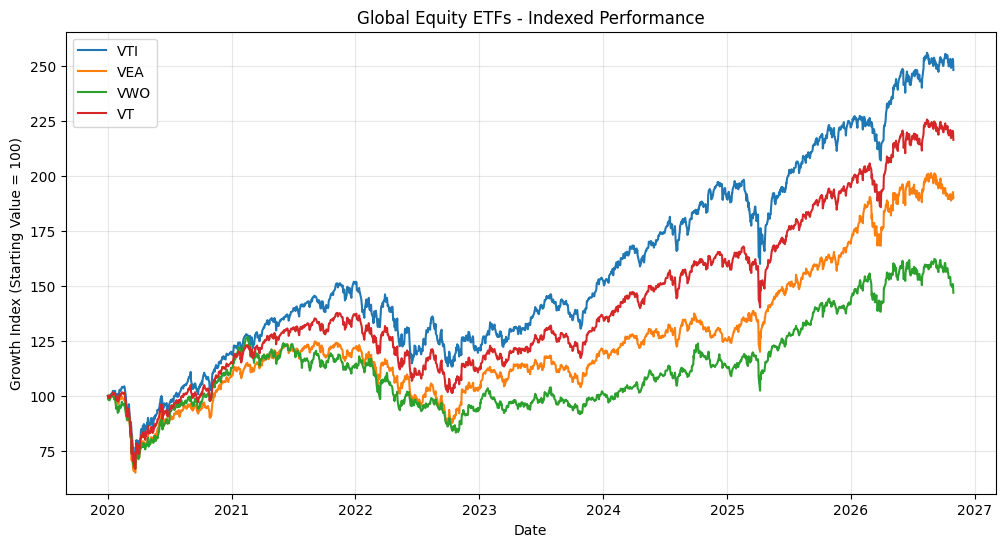

In [7]:

# Create a new chart with a width of 12 inches and height of 6
plt.figure(figsize=(12, 6))

# Loop through each ETF in our tickers list
# Each iteration adds one ETF line to the chart
for ticker in tickers:

    # Plot the ETF's indexed performance over time
    plt.plot(
        indexed_prices.index,       # X-axis: dates
        indexed_prices[ticker],     # Y-axis: indexed values
        label=ticker                # Name displayed in the legend
    )

# Add a descriptive chart title
plt.title("Global Equity ETFs - Indexed Performance")

# Label the horizontal axis
plt.xlabel("Date")

# Label the vertical axis
plt.ylabel("Growth Index (Starting Value = 100)")

# Display the legend identifying each ETF
plt.legend()

# Add a light grid to make values easier to read
plt.grid(alpha=0.3)

# Render the chart
plt.show()


In [8]:

# ---------------------------------------------------------
# STEP 5: EXPORT CLEANED DATA FOR REUSE
# ---------------------------------------------------------

# Save our cleaned ETF prices to a CSV file.
#
# A CSV (Comma-Separated Values) file stores tabular data
# and can be opened with Excel, Python or other applications.
#
# index=True ensures the dates are saved as the first column.

prices.to_csv("etf_prices.csv", index=True)

# Confirm that the file has been created.

print("Dataset saved successfully!")


Dataset saved successfully!
